# Semana 9: Hopfield: memoria asociativa, ruido y capacidad

**Objetivo:** medir cuánto ruido tolera una red de Hopfield al recuperar un patrón y cuántos
patrones puede guardar antes de fallar.

## Modelo

$N$ neuronas bipolares $s_i \in \{-1, +1\}$. Los $P$ patrones $\boldsymbol{\xi}^\mu$ se guardan con
la regla de Hebb:

$$W_{ij} = \frac{1}{N}\sum_{\mu=1}^{P} \xi_i^\mu \xi_j^\mu, \qquad W_{ii} = 0$$

La recuperación actualiza una neurona a la vez, $s_i \leftarrow \text{sign}\big(\sum_j W_{ij}s_j\big)$,
lo que nunca aumenta la energía $E = -\tfrac12 \mathbf{s}^\top W \mathbf{s}$. La calidad se mide con
el **solapamiento**

$$m = \frac{1}{N}\sum_i \xi_i\, s_i \in [-1, 1]$$

($m = 1$: recuperación perfecta). La teoría predice una capacidad máxima de
$P_\text{max} \approx 0.138\,N$.

**Diseño:** $N = 100$ y patrones aleatorios independientes (con semilla). No se usan patrones
que sean uno el negativo del otro: con la regla de Hebb, $\boldsymbol\xi$ y $-\boldsymbol\xi$
producen la misma matriz $W$, así que contarían como una sola memoria.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import train_hopfield
from computational_neuroscience.outputs import save_data, save_figure

WEEK = 9
N = 100
TRIALS = 20
rng = np.random.default_rng(9)


def random_patterns(count: int) -> np.ndarray:
    return rng.choice([-1.0, 1.0], size=(count, N))


def corrupt(pattern: np.ndarray, flips: int) -> np.ndarray:
    corrupted = pattern.copy()
    corrupted[rng.choice(N, size=flips, replace=False)] *= -1
    return corrupted


def recall_statistics(network, patterns: np.ndarray, flip_fraction: float) -> tuple[float, float]:
    overlaps, exact = [], []
    for pattern in patterns:
        for _ in range(TRIALS):
            state = network.recall(corrupt(pattern, round(flip_fraction * N)), seed=int(rng.integers(1_000_000))).state
            overlaps.append(state @ pattern / N)
            exact.append(np.array_equal(state, pattern))
    return float(np.mean(overlaps)), float(np.mean(exact))


# Experiment 1: noise tolerance with a light load (P = 5, P/N = 0.05).
memory = random_patterns(5)
network = train_hopfield(memory)
flip_fractions = np.linspace(0.0, 0.45, 10)
noise_results = np.array([recall_statistics(network, memory, fraction) for fraction in flip_fractions])

# Experiment 2: capacity, 10 % noise, increasing load.
loads = np.arange(2, 27, 2)
capacity_results = []
for count in loads:
    patterns = random_patterns(count)
    capacity_results.append(recall_statistics(train_hopfield(patterns), patterns, 0.10))
capacity_results = np.array(capacity_results)

## Figura

Izquierda: solapamiento final y fracción de recuperaciones exactas frente al ruido inicial, con
5 patrones guardados. Derecha: lo mismo frente a la carga $P/N$, con 10 % de ruido; la línea
discontinua marca la capacidad teórica 0.138.

Saved: weeks/week_09_hopfield_noise/outputs/hopfield_noise_recall.png
Saved: weeks/week_09_hopfield_noise/outputs/hopfield_noise_recall.npz


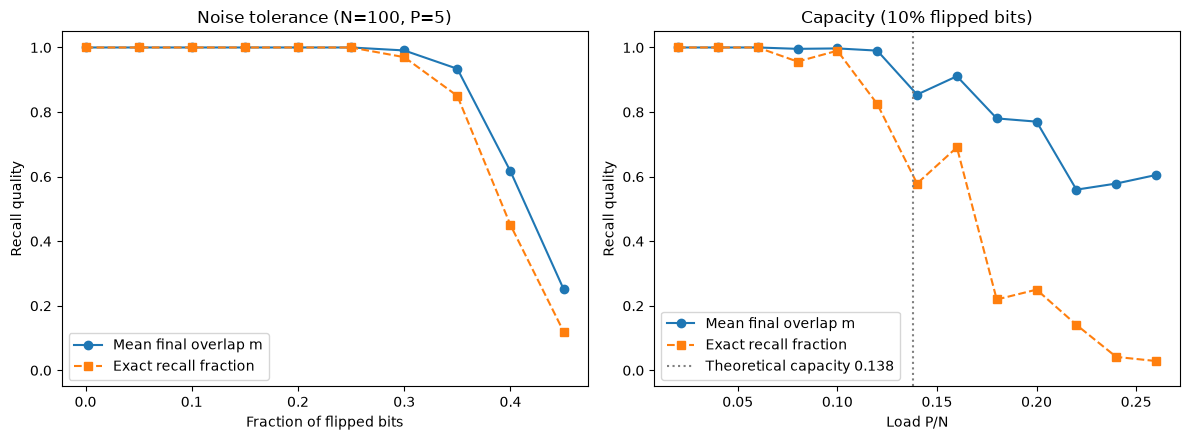

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(flip_fractions, noise_results[:, 0], "o-", label="Mean final overlap m")
axes[0].plot(flip_fractions, noise_results[:, 1], "s--", label="Exact recall fraction")
axes[0].set(xlabel="Fraction of flipped bits", ylabel="Recall quality", ylim=(-0.05, 1.05),
            title=f"Noise tolerance (N={N}, P=5)")
axes[0].legend()
axes[1].plot(loads / N, capacity_results[:, 0], "o-", label="Mean final overlap m")
axes[1].plot(loads / N, capacity_results[:, 1], "s--", label="Exact recall fraction")
axes[1].axvline(0.138, color="grey", linestyle=":", label="Theoretical capacity 0.138")
axes[1].set(xlabel="Load P/N", ylabel="Recall quality", ylim=(-0.05, 1.05), title="Capacity (10% flipped bits)")
axes[1].legend()
save_figure(WEEK, figure, "hopfield_noise_recall.png")
save_data(WEEK, "hopfield_noise_recall.npz", flip_fraction=flip_fractions, noise_overlap=noise_results[:, 0],
          noise_exact=noise_results[:, 1], load=loads / N, load_overlap=capacity_results[:, 0], load_exact=capacity_results[:, 1])

## Validación

- Sin ruido y con poca carga, cada patrón guardado es un punto fijo: recuperación exacta 100 %.
- La energía nunca aumenta durante la recuperación.
- La calidad cae al aumentar el ruido y al superar la capacidad teórica.

In [3]:
for pattern in memory:
    result = network.recall(pattern, seed=0)
    assert np.array_equal(result.state, pattern)
noisy_result = network.recall(corrupt(memory[0], 30), seed=1)
assert np.all(np.diff(noisy_result.energy_history) <= 1e-12)
assert noise_results[0, 1] == 1.0
assert noise_results[-1, 0] < noise_results[0, 0]
below, above = capacity_results[loads / N <= 0.06, 1].mean(), capacity_results[loads / N >= 0.2, 1].mean()
assert below > 0.9 and above < 0.5, (below, above)
print(f"Exact recall: {below:.0%} for P/N <= 0.06, {above:.0%} for P/N >= 0.2")

Exact recall: 100% for P/N <= 0.06, 12% for P/N >= 0.2


## Interpretación y límites

- Con poca carga, cada patrón tiene una cuenca de atracción amplia: se corrige hasta ~30 % de
  ruido. Cerca de 50 % el estado inicial ya no se parece al patrón.
- Al aumentar $P/N$, la interferencia entre patrones crea **estados espurios** y la recuperación
  exacta colapsa antes de la capacidad teórica (definida para $N \to \infty$ y error pequeño).
- Los patrones aleatorios son el mejor caso; patrones correlacionados reducen la capacidad.

**Para tu entrega:** registra también los fallos, el estado al que converge la red cuando no
recupera el patrón y su solapamiento con los demás patrones guardados.